# Cupcake – Preprocessing & Binning

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler

## 1. Load & inspect

In [2]:
df = pd.read_csv('cupcake(Task 2 Slide 5).csv')
display(df.head())
print(df.shape)
print(df.dtypes)
print(df.isna().sum())

,Month,MonthIndex,Cupcake,AdSpend,Orders
0,2010-01,0,4,100.0,82
1,2010-02,1,84,137.0,326
2,2010-03,2,88,174.0,337
3,2010-04,3,82,211.0,318
4,2010-05,4,80,248.0,313


(160, 5)
Month          object
MonthIndex      int64
Cupcake         int64
AdSpend       float64
Orders          int64
dtype: object
Month         0
MonthIndex    0
Cupcake       0
AdSpend       8
Orders        0
dtype: int64


## 2–3. Inputs / target, time-ordered 80/20 split

In [3]:
X = df[['Cupcake', 'AdSpend']]
y = df['Orders']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)
print(X_train.shape, X_test.shape)

(128, 2) (32, 2)


## 4. Median imputation (fit on train only)

In [4]:
imp = SimpleImputer(strategy='median')
X_train_i = pd.DataFrame(imp.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_i  = pd.DataFrame(imp.transform(X_test),      columns=X.columns, index=X_test.index)
print(dict(zip(X.columns, imp.statistics_)))
print(X_train_i.isna().sum().sum(), X_test_i.isna().sum().sum())

{'Cupcake': 48.0, 'AdSpend': 263.0}
0 0


## 5. StandardScaler vs MinMaxScaler (fit on train only)

In [5]:
ss, mm = StandardScaler(), MinMaxScaler()
X_train_ss = pd.DataFrame(ss.fit_transform(X_train_i), columns=X.columns)
X_test_ss  = pd.DataFrame(ss.transform(X_test_i),      columns=X.columns)
X_train_mm = pd.DataFrame(mm.fit_transform(X_train_i), columns=X.columns)
X_test_mm  = pd.DataFrame(mm.transform(X_test_i),      columns=X.columns)

summary = pd.concat({
    'Raw':    X_train_i.describe().loc[['mean','std','min','max']],
    'Standard': X_train_ss.describe().loc[['mean','std','min','max']],
    'MinMax': X_train_mm.describe().loc[['mean','std','min','max']],
}).round(3)
display(summary)
print('Test ranges (StandardScaler):'); display(X_test_ss.describe().loc[['min','max']].round(3))
print('Test ranges (MinMaxScaler):');   display(X_test_mm.describe().loc[['min','max']].round(3))

Cupcake  AdSpend
Raw      mean   48.469  267.906
         std    23.100   98.356
         min     4.000  100.000
         max    92.000  448.000
Standard mean    0.000    0.000
         std     1.004    1.004
         min    -1.933   -1.714
         max     1.892    1.838
MinMax   mean    0.505    0.482
         std     0.262    0.283
         min     0.000    0.000
         max     1.000    1.000

Test ranges (StandardScaler):


,Cupcake,AdSpend
min,-1.889,-1.673
max,2.240,1.726


Test ranges (MinMaxScaler):


,Cupcake,AdSpend
min,0.011,0.011
max,1.091,0.968


- **StandardScaler**: train mean 0, std 1; unbounded range.
- **MinMaxScaler**: train range [0, 1]; test values can fall outside [0, 1] since the min/max come from train only.

## 6. cut vs qcut on Cupcake (full CSV)

In [6]:
labels = ['Low', 'Medium', 'High']
df['Cupcake_cut']  = pd.cut(df['Cupcake'],  bins=3, labels=labels)
df['Cupcake_qcut'] = pd.qcut(df['Cupcake'], q=3,    labels=labels)

print('cut edges: ', pd.cut(df['Cupcake'],  bins=3).cat.categories.tolist())
print('qcut edges:', pd.qcut(df['Cupcake'], q=3).cat.categories.tolist())
cut_counts, qcut_counts = df['Cupcake_cut'].value_counts().reindex(labels), df['Cupcake_qcut'].value_counts().reindex(labels)
print(pd.DataFrame({'cut': cut_counts, 'qcut': qcut_counts}))

cut edges:  [Interval(3.904, 36.0, closed='right'), Interval(36.0, 68.0, closed='right'), Interval(68.0, 100.0, closed='right')]
qcut edges: [Interval(3.999, 37.0, closed='right'), Interval(37.0, 60.0, closed='right'), Interval(60.0, 100.0, closed='right')]
        cut  qcut
Low      53    56
Medium   69    51
High     38    53


## 7. Bin counts

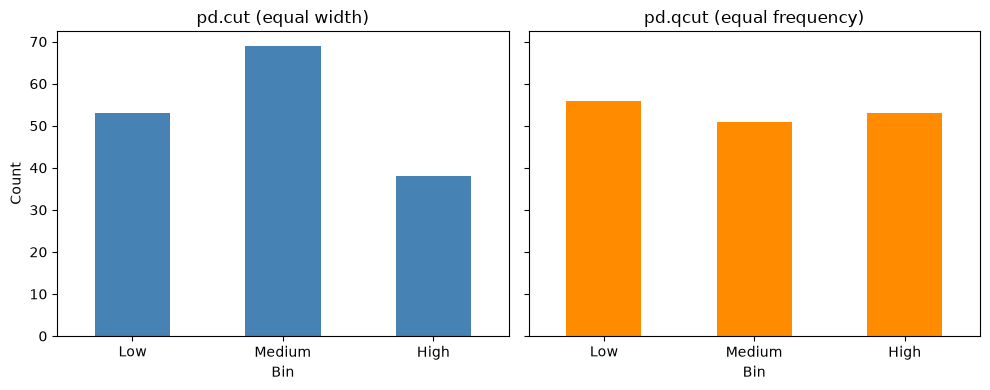

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
cut_counts.plot.bar(ax=ax[0], color='steelblue', rot=0, title='pd.cut (equal width)')
qcut_counts.plot.bar(ax=ax[1], color='darkorange', rot=0, title='pd.qcut (equal frequency)')
for a in ax: a.set_xlabel('Bin'); a.set_ylabel('Count')
plt.tight_layout(); plt.show()

**Difference**
- `cut` splits the *value range* into 3 equal-width intervals, so counts depend on how the data is distributed and can be very uneven (skewed data or outliers leave some bins nearly empty).
- `qcut` splits at *quantiles* (33rd/66th percentiles), so bins have roughly equal counts but unequal widths.